## Common Algorithms for Upstream E&P

#### Keith R. Holdaway FGS

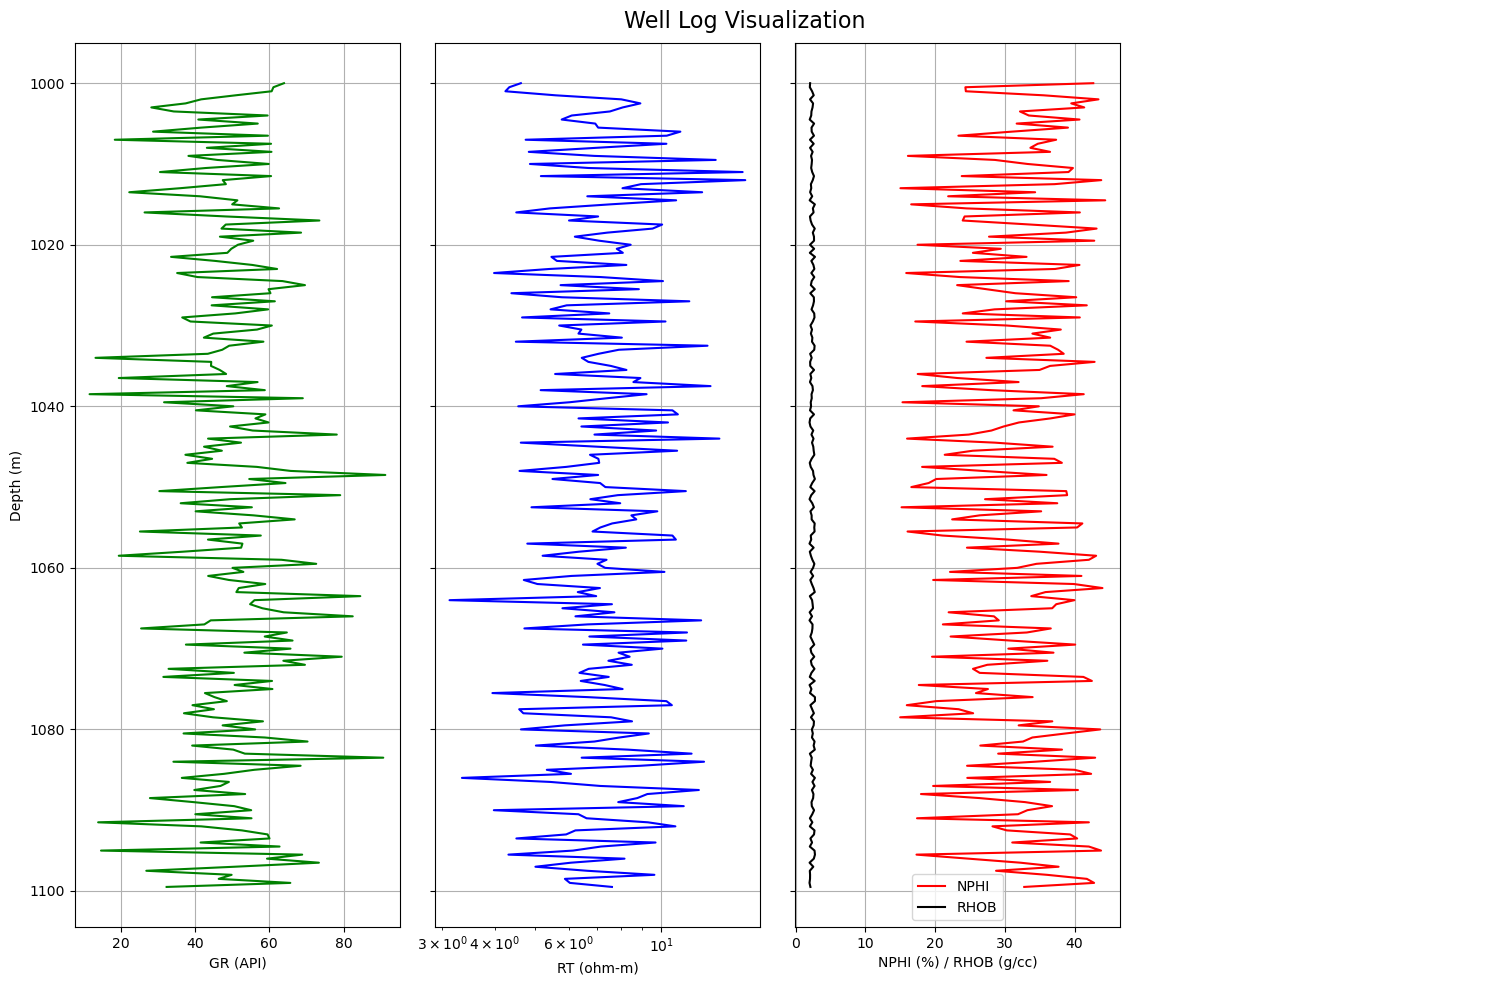

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def visualize_well_logs():
    # Load sample well log data
    data = {
        'Depth': np.arange(1000, 1100, 0.5),
        'GR': np.random.normal(50, 15, 200),
        'RT': np.random.lognormal(2, 0.3, 200),
        'NPHI': np.random.uniform(0.15, 0.45, 200),
        'RHOB': np.random.uniform(2.0, 2.8, 200)
    }
    df = pd.DataFrame(data)
    
    # Create log plot
    fig, axes = plt.subplots(1, 4, figsize=(15, 10), sharey=True)
    fig.suptitle('Well Log Visualization', fontsize=16)
    
    # Gamma Ray track
    axes[0].plot(df['GR'], df['Depth'], color='green')
    axes[0].set_xlabel('GR (API)')
    axes[0].set_ylabel('Depth (m)')
    axes[0].grid(True)
    
    # Resistivity track
    axes[1].semilogx(df['RT'], df['Depth'], color='blue')
    axes[1].set_xlabel('RT (ohm-m)')
    axes[1].grid(True)
    
    # Porosity track
    axes[2].plot(df['NPHI']*100, df['Depth'], color='red', label='NPHI')
    axes[2].plot(df['RHOB'], df['Depth'], color='black', label='RHOB')
    axes[2].set_xlabel('NPHI (%) / RHOB (g/cc)')
    axes[2].legend()
    axes[2].grid(True)
    
    # Empty track for future use
    axes[3].axis('off')
    
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

visualize_well_logs()

## 2. Petrophysical Calculations with NumPy

In [2]:
import numpy as np
import pandas as pd

def petrophysical_analysis():
    # Sample data
    depth = np.arange(3000, 3200, 0.5)
    nphi = np.random.uniform(0.1, 0.4, len(depth))
    rhob = np.random.uniform(2.0, 2.8, len(depth))
    gr = np.random.normal(60, 20, len(depth))
    rt = np.random.lognormal(2, 0.4, len(depth))
    
    # Calculate shale volume using linear GR method
    gr_clean = 30  # API
    gr_shale = 120  # API
    vsh = (gr - gr_clean) / (gr_shale - gr_clean)
    vsh = np.clip(vsh, 0, 1)  # Ensure between 0-1
    
    # Calculate porosity (simplified)
    phi = (nphi + (2.65 - rhob)/2.65) / 2
    
    # Calculate water saturation (Archie equation - simplified)
    a, m, n = 1.0, 2.0, 2.0  # Archie parameters
    rw = 0.1  # Ohm-m @ formation temperature
    sw = ((a * rw) / (phi**m * rt)) ** (1/n)
    sw = np.clip(sw, 0.01, 1)  # Ensure between 0-1
    
    # Create DataFrame
    results = pd.DataFrame({
        'Depth': depth,
        'GR': gr,
        'RT': rt,
        'NPHI': nphi,
        'RHOB': rhob,
        'VSH': vsh,
        'PHI': phi,
        'SW': sw
    })
    
    # Print statistics
    print("\nPetrophysical Analysis Results Summary:")
    print(results.describe())
    
    return results

df = petrophysical_analysis()


Petrophysical Analysis Results Summary:
             Depth          GR          RT        NPHI        RHOB  \
count   400.000000  400.000000  400.000000  400.000000  400.000000   
mean   3099.750000   59.793344    7.806517    0.251780    2.407328   
std      57.807151   20.407776    3.190431    0.084813    0.237581   
min    3000.000000   -1.584486    2.395933    0.100439    2.001241   
25%    3049.875000   45.798836    5.640933    0.180162    2.198334   
50%    3099.750000   59.572964    7.282594    0.259473    2.403416   
75%    3149.625000   74.170205    9.216961    0.326427    2.625289   
max    3199.500000  133.739093   22.164544    0.399696    2.799303   

              VSH         PHI          SW  
count  400.000000  400.000000  400.000000  
mean     0.337183    0.171677    0.716646  
std      0.212438    0.063522    0.224811  
min      0.000000    0.023165    0.254932  
25%      0.175543    0.123974    0.530809  
50%      0.328588    0.174707    0.708910  
75%      0.490780   

## 3. Machine Learning for Lithology Classification (Scikit-learn)

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

def lithology_classification():
    # Create synthetic dataset
    np.random.seed(42)
    n_samples = 1000
    
    # Features: GR, RT, NPHI, RHOB
    data = {
        'GR': np.concatenate([
            np.random.normal(30, 5, n_samples//4),  # Sandstone
            np.random.normal(75, 15, n_samples//4),  # Shale
            np.random.normal(50, 10, n_samples//4),  # Limestone
            np.random.normal(100, 20, n_samples//4)   # Coal
        ]),
        'RT': np.concatenate([
            np.random.lognormal(2.5, 0.3, n_samples//4),
            np.random.lognormal(1.8, 0.4, n_samples//4),
            np.random.lognormal(2.2, 0.3, n_samples//4),
            np.random.lognormal(3.0, 0.5, n_samples//4)
        ]),
        'NPHI': np.concatenate([
            np.random.uniform(0.25, 0.35, n_samples//4),
            np.random.uniform(0.15, 0.25, n_samples//4),
            np.random.uniform(0.20, 0.30, n_samples//4),
            np.random.uniform(0.40, 0.50, n_samples//4)
        ]),
        'RHOB': np.concatenate([
            np.random.uniform(2.3, 2.5, n_samples//4),
            np.random.uniform(2.5, 2.7, n_samples//4),
            np.random.uniform(2.4, 2.6, n_samples//4),
            np.random.uniform(1.3, 1.6, n_samples//4)
        ])
    }
    
    # Target: Lithology (0=Sandstone, 1=Shale, 2=Limestone, 3=Coal)
    target = np.concatenate([
        np.zeros(n_samples//4),
        np.ones(n_samples//4),
        np.full(n_samples//4, 2),
        np.full(n_samples//4, 3)
    ])
    
    df = pd.DataFrame(data)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        df, target, test_size=0.3, random_state=42
    )
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train model
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    # Evaluate
    y_pred = model.predict(X_test_scaled)
    print("\nLithology Classification Report:")
    print(classification_report(y_test, y_pred, 
                               target_names=['Sandstone', 'Shale', 'Limestone', 'Coal']))
    
    # Feature importance
    print("\nFeature Importances:")
    for name, importance in zip(df.columns, model.feature_importances_):
        print(f"{name}: {importance:.3f}")
    
    return model, scaler

model, scaler = lithology_classification()


Lithology Classification Report:
              precision    recall  f1-score   support

   Sandstone       0.99      0.99      0.99        72
       Shale       0.99      0.95      0.97        78
   Limestone       0.94      0.97      0.95        75
        Coal       1.00      1.00      1.00        75

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300


Feature Importances:
GR: 0.332
RT: 0.046
NPHI: 0.299
RHOB: 0.323


## 4. Neural Network for Permeability Prediction (TensorFlow/Keras)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0876 - mae: 0.2276 - val_loss: 0.0219 - val_mae: 0.1062
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0245 - mae: 0.1201 - val_loss: 0.0191 - val_mae: 0.0934
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0225 - mae: 0.1099 - val_loss: 0.0182 - val_mae: 0.0903
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0215 - mae: 0.1077 - val_loss: 0.0188 - val_mae: 0.0916
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0236 - mae: 0.1051 - val_loss: 0.0183 - val_mae: 0.0870
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0185 - mae: 0.0957 - val_loss: 0.0174 - val_mae: 0.0856
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0191 - mae: 0.0959 - val_loss: 0.0184 - val_mae: 0.0866
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0170 - mae: 0.0921 - val_loss: 0.0172 - val_mae: 0.0837
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.014

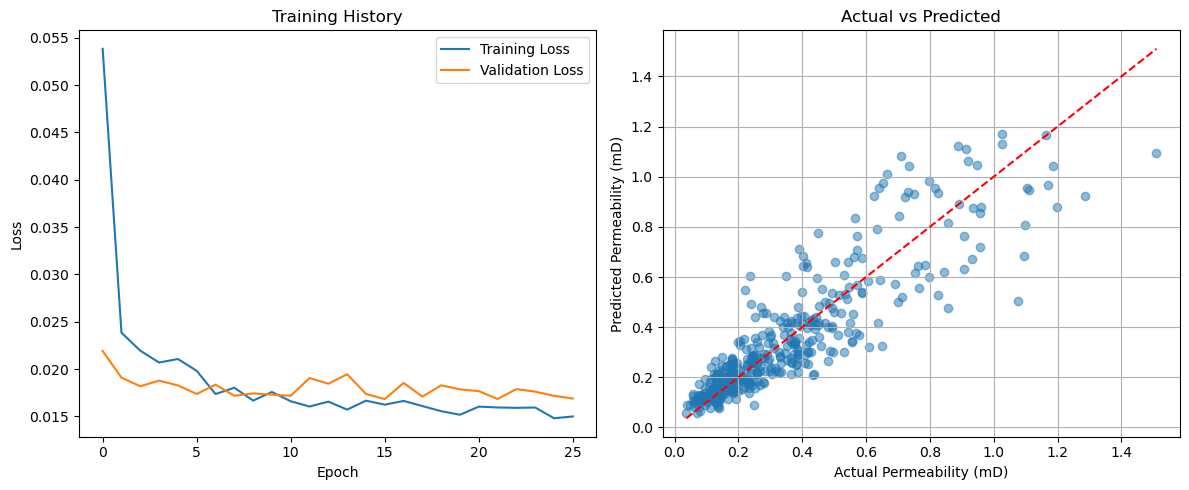

In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import warnings

# Suppress TensorFlow deprecation warnings
tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore', category=UserWarning)

def permeability_prediction():
    # Create synthetic dataset
    np.random.seed(42)
    n_samples = 2000
    
    # Features: Porosity, Vshale, Sw
    X = np.column_stack([
        np.random.uniform(0.05, 0.35, n_samples),  # Porosity
        np.random.uniform(0, 0.7, n_samples),      # Vshale
        np.random.uniform(0.2, 1.0, n_samples)     # Sw
    ])
    
    # Target: Permeability (log-normal distribution)
    log_mean = -1 + 5*X[:,0] - 2*X[:,1] - X[:,2]
    y = np.exp(np.random.normal(log_mean, 0.3))
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Build neural network with explicit input layer
    model = tf.keras.Sequential([
        tf.keras.layers.InputLayer(input_shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    
    # Add learning rate schedule
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=0.001,
        decay_steps=10000,
        decay_rate=0.9)
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
        loss='mse',
        metrics=['mae']
    )
    
    # Add early stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )
    
    # Train with validation split
    history = model.fit(
        X_train_scaled, y_train,
        epochs=100,
        batch_size=32,
        validation_split=0.2,
        callbacks=[early_stopping],
        verbose=1
    )
    
    # Evaluate
    y_pred = model.predict(X_test_scaled).flatten()
    
    print("\nPermeability Prediction Results:")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
    print(f"R²: {r2_score(y_test, y_pred):.2f}")
    
    # Plot training history
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training History')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    
    # Plot actual vs predicted
    plt.subplot(1, 2, 2)
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.xlabel('Actual Permeability (mD)')
    plt.ylabel('Predicted Permeability (mD)')
    plt.title('Actual vs Predicted')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    return model, scaler

perm_model, perm_scaler = permeability_prediction()

## 5. Geospatial Analysis for Reservoir Mapping (Geopandas)

In [5]:
# pip install geopandas

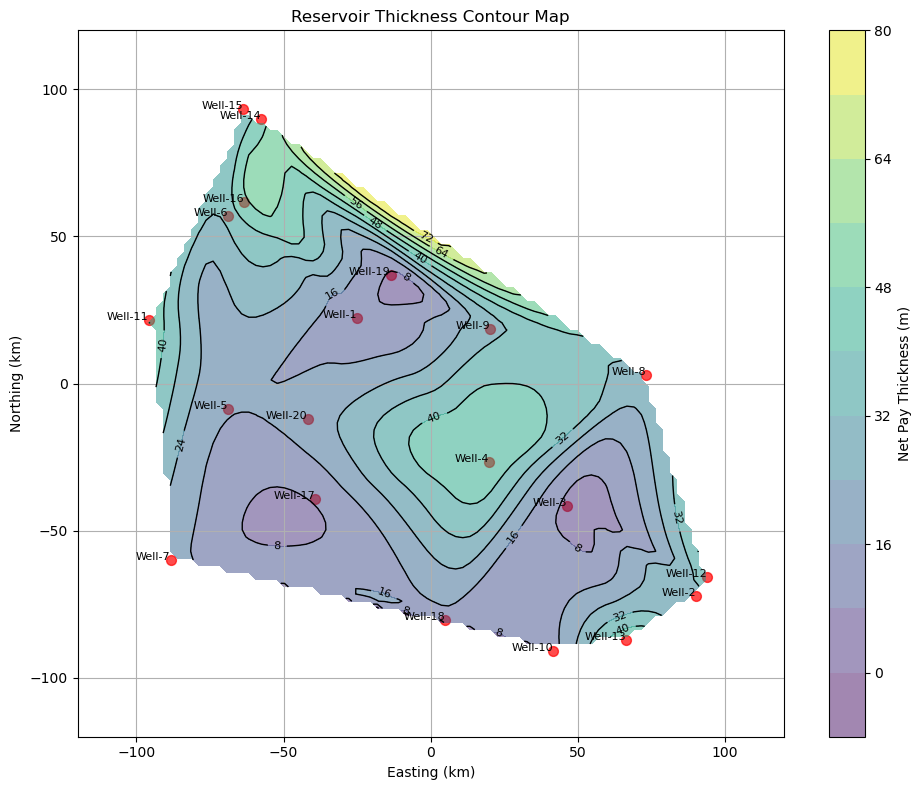

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import griddata  # Added import

def reservoir_mapping():
    # Create synthetic reservoir data
    np.random.seed(42)
    n_wells = 20
    
    # Generate random well locations within a bounding box
    x = np.random.uniform(-100, 100, n_wells)
    y = np.random.uniform(-100, 100, n_wells)
    
    # Generate random reservoir properties
    thickness = np.random.uniform(5, 50, n_wells)
    porosity = np.random.uniform(0.1, 0.25, n_wells)
    oil_saturation = np.random.uniform(0.5, 0.85, n_wells)
    
    # Create GeoDataFrame
    gdf = gpd.GeoDataFrame(
        {
            'Well': [f'Well-{i}' for i in range(1, n_wells+1)],
            'Thickness': thickness,
            'Porosity': porosity,
            'Oil_Saturation': oil_saturation,
            'STOIIP': thickness * porosity * oil_saturation * 1000  # Simplified STOIIP calculation
        },
        geometry=gpd.points_from_xy(x, y)
    )
    
    # Create contour plot for thickness
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot wells
    gdf.plot(ax=ax, color='red', markersize=50, alpha=0.7)
    
    # Add labels
    for x, y, label in zip(gdf.geometry.x, gdf.geometry.y, gdf['Well']):
        ax.text(x, y, label, fontsize=8, ha='right')
    
    # Create grid for contouring
    xi = np.linspace(-120, 120, 100)
    yi = np.linspace(-120, 120, 100)
    xi, yi = np.meshgrid(xi, yi)
    
    # Interpolate thickness values using griddata
    zi = griddata(
        (gdf.geometry.x, gdf.geometry.y),
        gdf['Thickness'],
        (xi, yi),
        method='cubic'
    )
    
    # Plot contours
    cs = ax.contour(xi, yi, zi, levels=10, linewidths=1, colors='black')
    ax.clabel(cs, inline=True, fontsize=8)
    cntr = ax.contourf(xi, yi, zi, levels=10, cmap="viridis", alpha=0.5)
    
    # Add colorbar
    fig.colorbar(cntr, ax=ax, label='Net Pay Thickness (m)')
    
    ax.set_title('Reservoir Thickness Contour Map')
    ax.set_xlabel('Easting (km)')
    ax.set_ylabel('Northing (km)')
    ax.grid(True)
    plt.tight_layout()
    plt.show()
    
    return gdf

reservoir_data = reservoir_mapping()

## 6. Time Series Analysis for Production Forecasting (Statsmodels)

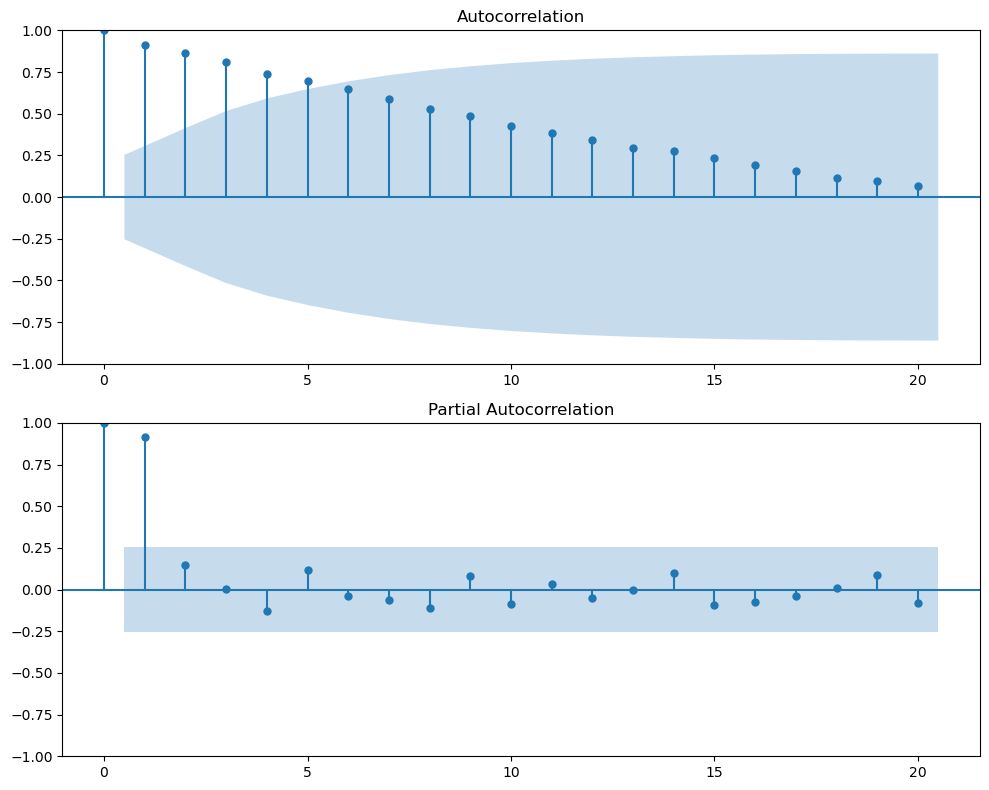

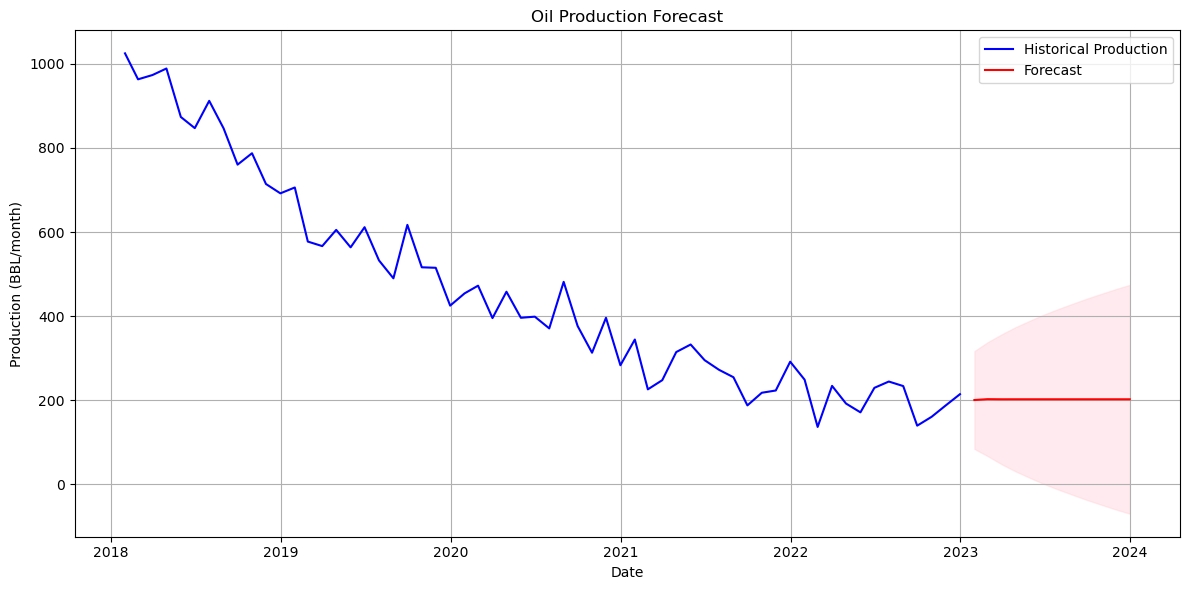


Production Forecast Summary:
              Forecast   Lower_CI    Upper_CI
2023-01-31  200.627915  84.290979  316.964852
2023-02-28  202.658667  67.644427  337.672908
2023-03-31  202.362606  47.677897  357.047316
2023-04-30  202.405769  30.727419  374.084118
2023-05-31  202.399476  15.205340  389.593612
2023-06-30  202.400393   0.889576  403.911211
2023-07-31  202.400260 -12.476553  417.277072
2023-08-31  202.400279 -25.058313  429.858871
2023-09-30  202.400276 -36.979730  441.780283
2023-10-31  202.400277 -48.334967  453.135521
2023-11-30  202.400277 -59.197769  463.998323
2023-12-31  202.400277 -69.627135  474.427689


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def production_forecasting():
    # Create synthetic production data
    np.random.seed(42)
    months = 60
    index = pd.date_range(start='2018-01-01', periods=months, freq='ME')  # Changed 'M' to 'ME'
    
    # Create declining production with noise
    decline_rate = 0.03  # 3% monthly decline
    base_production = 1000  # BBL/month
    noise = np.random.normal(0, 50, months)
    
    production = base_production * (1 - decline_rate) ** np.arange(months) + noise
    production = np.maximum(production, 50)  # Don't go below 50 BBL/month
    
    # Create DataFrame
    df = pd.DataFrame({'Production': production}, index=index)
    
    # Plot ACF and PACF to determine ARIMA parameters
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    plot_acf(df['Production'], ax=ax1, lags=20)
    plot_pacf(df['Production'], ax=ax2, lags=20)
    plt.tight_layout()
    plt.show()
    
    # Fit ARIMA model
    model = ARIMA(df['Production'], order=(1, 1, 1))
    results = model.fit()
    
    # Forecast next 12 months
    forecast_months = 12
    forecast = results.get_forecast(steps=forecast_months)
    forecast_index = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), 
                                 periods=forecast_months, freq='ME')  # Changed 'M' to 'ME'
    
    # Create forecast DataFrame
    forecast_df = pd.DataFrame({
        'Forecast': forecast.predicted_mean,
        'Lower_CI': forecast.conf_int()['lower Production'],
        'Upper_CI': forecast.conf_int()['upper Production']
    }, index=forecast_index)
    
    # Plot results
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, df['Production'], label='Historical Production', color='blue')
    plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecast', color='red')
    plt.fill_between(forecast_df.index, 
                    forecast_df['Lower_CI'], 
                    forecast_df['Upper_CI'], 
                    color='pink', alpha=0.3)
    plt.title('Oil Production Forecast')
    plt.xlabel('Date')
    plt.ylabel('Production (BBL/month)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # Print forecast summary
    print("\nProduction Forecast Summary:")
    print(forecast_df)
    
    return df, forecast_df

historical, forecast = production_forecasting()